# CNN-Based Classification of Images Containing One Person or Multiple People
**Course work – Neural Networks**
**Topic:** Comparison of convolutional neural network models for image classification

**Aim:** build a classifier that decides whether a photograph shows a **single person** or a **group of people** (3 or more), and compare three convolutional neural network (CNN) models on this task.

**Research questions**
1. Which CNN architecture – a custom CNN, ResNet50 or MobileNetV2 – classifies the images best?
2. Does **transfer learning** (starting from ImageNet weights) improve the results compared with training from scratch?
3. Does **data augmentation** reduce over-fitting and improve the results?
4. What is the **computational cost** (size, training time, prediction speed) of each model?
5. Which images are misclassified, and why?

## Workflow
| Step | Content | Course-work chapter |
|---|---|---|
| 0 | Libraries and settings | – |
| 1 | Build the labelled dataset from MS COCO and split it into train / validation / test | Dataset |
| 2 | Dataset analysis (class balance, image sizes, people per image) | Dataset analysis |
| 3 | Preprocessing and data augmentation | Preprocessing |
| 4 | The three CNN models | Models |
| 5 | Training of 6 experiments | Experiments |
| 6 | Evaluation: accuracy, precision, recall, F1, confusion matrices | Results |
| 7 | Effect of transfer learning and data augmentation | Discussion |
| 8 | Computational efficiency | Discussion |
| 9 | Error analysis | Error analysis |
| 10 | Demonstration on your own photo | Demonstration |
| 11 | Conclusions | Conclusion |

**How to run (Google Colab):** *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all* (about 30–40 minutes).
For a fast check that everything runs, set `QUICK_TEST = True` in Step 0.

## Step 0 – Libraries and settings

In [12]:
import os, json, time, zipfile, random, gc
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

sns.set_theme(style="whitegrid")
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "none (switch the runtime to GPU!)")

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [13]:
# ---------------- SETTINGS ----------------
QUICK_TEST      = False         # True = small dataset and 2 epochs, only to check that the notebook runs
IMG_SIZE        = 160           # every image is resized to IMG_SIZE x IMG_SIZE pixels
BATCH           = 32            # images per training step
EPOCHS          = 10            # maximum number of epochs (early stopping can stop sooner)
SEED            = 42            # fixed random seed -> repeatable results

N_PER_CLASS     = 1500          # images per class (balanced dataset)
GROUP_MIN       = 3             # "group" = at least 3 clearly visible people
MIN_PERSON_FRAC = 0.02          # a person is "clearly visible" if its box covers >= 2 % of the image area
COCO_SPLIT      = "train2017"   # COCO annotation file used; "val2017" is smaller

if QUICK_TEST:
    N_PER_CLASS, EPOCHS, COCO_SPLIT = 120, 2, "val2017"

CLASS_NAMES = ["single", "group"]          # label 0 = single, label 1 = group
WORK = Path(os.environ.get("WORK_DIR", "/content/work"))
(WORK / "images").mkdir(parents=True, exist_ok=True)
(WORK / "weights").mkdir(exist_ok=True)

random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)

## Step 1 – Dataset
The images are real photographs from the public **MS COCO 2017** dataset. In COCO every person is marked with a bounding box, so the class label can be created automatically from the annotations:

| Class | Rule |
|---|---|
| **single** (label 0) | exactly **one** annotated person, and this person is clearly visible |
| **group** (label 1) | **3 or more** clearly visible people |
| *not used* | no people, exactly 2 people (borderline case), crowd annotations, or only very small people |

A person is *clearly visible* when its box covers at least 2 % of the image:
$\text{person size} = \dfrac{w_{box}\cdot h_{box}}{W_{image}\cdot H_{image}} \ge 0.02$

The number of people (`n_people`) and the average person size (`person_size`) are stored as well. They are **not** used for training – only for the error analysis in Step 9.

In [14]:
# 1a) Download the COCO annotations and decide the label of every image
ANN_URL = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"
ann_zip = WORK / "annotations.zip"
if not ann_zip.exists():
    with requests.get(ANN_URL, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(ann_zip, "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)

with zipfile.ZipFile(ann_zip) as z:
    coco = json.load(z.open(f"annotations/instances_{COCO_SPLIT}.json"))
images_info = {im["id"]: im for im in coco["images"]}

people = {}                                        # image id -> list of person annotations
for a in coco["annotations"]:
    if a["category_id"] == 1:                      # COCO category 1 = person
        people.setdefault(a["image_id"], []).append(a)

rows = []
for image_id, anns in people.items():
    im = images_info[image_id]
    if any(a["iscrowd"] for a in anns):            # skip images with "crowd" regions
        continue
    sizes = [a["bbox"][2] * a["bbox"][3] / (im["width"] * im["height"]) for a in anns]   # box area / image area
    big = [s for s in sizes if s >= MIN_PERSON_FRAC]                                    # clearly visible people
    if len(sizes) == 1 and len(big) == 1:
        label = "single"
    elif len(big) >= GROUP_MIN:
        label = "group"
    else:
        continue
    rows.append(dict(image_id=image_id, url=im["coco_url"].replace("http://", "https://"),
                     width=im["width"], height=im["height"], label=label,
                     n_people=len(big), person_size=float(np.mean(big))))
del coco, images_info, people; gc.collect()     # free memory (the annotation file is large)

candidates = pd.DataFrame(rows)
print("Candidate images per class:")
print(candidates.label.value_counts().to_string())

Candidate images per class:
label
single    21436
group     11435


In [16]:
# 1b) Select a balanced set of images and download them
n = min(N_PER_CLASS, int(candidates.label.value_counts().min()))
df = pd.concat([candidates[candidates.label == c].sample(n, random_state=SEED) for c in CLASS_NAMES],
               ignore_index=True)
for c in CLASS_NAMES:
    (WORK / "images" / c).mkdir(exist_ok=True)
df["path"] = [str(WORK / "images" / r.label / f"{r.image_id}.jpg") for r in df.itertuples()]

session = requests.Session()
session.headers["User-Agent"] = "Mozilla/5.0 (course-work image download)"
download_errors = []                               # keeps the reason of failed downloads

def download_image(url, path):
    """Download one image (https first, then http; 3 attempts each).
    Returns True if a valid image file exists afterwards."""
    if Path(path).exists() and Path(path).stat().st_size > 0:
        return True
    for u in (url, url.replace("https://", "http://")):
        for attempt in range(3):
            try:
                r = session.get(u, timeout=30); r.raise_for_status()
                Path(path).write_bytes(r.content)
                Image.open(path).convert("RGB")    # check that the file is a valid image
                return True
            except Exception as e:
                last_error = f"{type(e).__name__}: {e}"
                time.sleep(1 + attempt)
    download_errors.append(last_error)
    Path(path).unlink(missing_ok=True)
    return False

# quick connection test with one image before starting the parallel download
if not download_image(df.url[0], df.path[0]):
    raise RuntimeError("Cannot download images from images.cocodataset.org.\n"
                       f"Reason: {download_errors[-1]}\n"
                       "Check the internet connection of the runtime (Runtime -> Restart session) and run this cell again.")

print(f"Downloading {len(df)} images ...")
with ThreadPoolExecutor(8) as pool:
    df["ok"] = list(pool.map(download_image, df.url, df.path))
print(f"Downloaded: {df.ok.sum()} | failed: {(~df.ok).sum()}")
if download_errors:
    print("Example reason of a failure:", download_errors[0])

df = df[df.ok].drop(columns="ok").reset_index(drop=True)
df["y"] = df.label.map({"single": 0, "group": 1})
per_class = df.y.value_counts().reindex([0, 1], fill_value=0)
if per_class.min() < 20:
    raise RuntimeError("Too few images were downloaded – run this cell again (already downloaded files are kept).")
print("Images ready:", len(df))

Downloaded: 3000 | failed: 0
Images ready: 3000


In [19]:
# 1c) Stratified split: 70 % train, 15 % validation, 15 % test (same class balance in every part)
train_df, rest_df = train_test_split(df, test_size=0.30, stratify=df.y, random_state=SEED)
val_df, test_df   = train_test_split(rest_df, test_size=0.50, stratify=rest_df.y, random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

split_table = pd.DataFrame({"train": train_df.label.value_counts(),
                            "validation": val_df.label.value_counts(),
                            "test": test_df.label.value_counts()}).T[CLASS_NAMES]
split_table["total"] = split_table.sum(axis=1)
print(split_table)

label       single  group  total
train         1050   1050   2100
validation     225    225    450
test           225    225    450


## Step 2 – Dataset analysis
* **Images per class** – checks that the dataset is balanced.
* **Original image sizes** – shows that the images have different sizes, so resizing is necessary.
* **People per image (group class)** – shows how many people the "group" images contain.

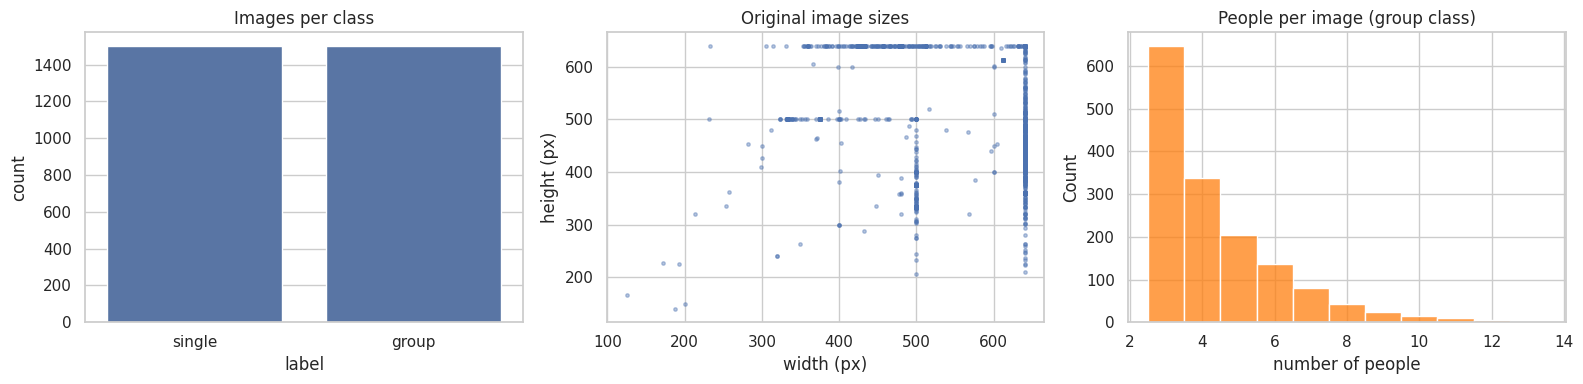

Average number of people and average person size per class:
        n_people  person_size
label                        
group      4.373        0.133
single     1.000        0.331


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, x="label", order=CLASS_NAMES, ax=ax[0]);   ax[0].set_title("Images per class")
ax[1].scatter(df.width, df.height, s=6, alpha=.4);                ax[1].set_title("Original image sizes")
ax[1].set_xlabel("width (px)"); ax[1].set_ylabel("height (px)")
sns.histplot(df[df.label == "group"].n_people, discrete=True, ax=ax[2], color="tab:orange")
ax[2].set_title("People per image (group class)"); ax[2].set_xlabel("number of people")
plt.tight_layout(); plt.show()

print("Average number of people and average person size per class:")
print(df.groupby("label")[["n_people", "person_size"]].mean().round(3))

## Step 3 – Preprocessing and data augmentation
* **Resize** every image to 160 × 160 pixels (bilinear interpolation) – all networks need the same input size.
* **Normalisation** of the pixel values is done *inside each model*, because each network expects a different range:
  custom CNN $x' = x/255 \in [0,1]$; MobileNetV2 $x' = x/127.5 - 1 \in [-1,1]$; ResNet50 RGB→BGR and subtraction of the ImageNet channel means.
* **Data augmentation** (active only during training): random horizontal flip, rotation up to ±8 % of a full turn (≈ ±29°), zoom up to ±15 % and contrast change up to ±20 %. Every epoch the network sees slightly different versions of the training images, which reduces over-fitting.
* **tf.data pipeline:** images are decoded once and cached in memory, the training set is shuffled every epoch, and the next batch is prepared while the GPU is training (prefetch).

In [21]:
def load_image(path, label):
    """Read a file, decode it as RGB and resize it to IMG_SIZE x IMG_SIZE (kept as uint8 to save memory)."""
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return tf.cast(tf.round(img), tf.uint8), label

def make_dataset(frame, training):
    ds = tf.data.Dataset.from_tensor_slices((frame.path.values.astype(str), frame.y.values.astype("float32")))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).cache()      # decode every image only once
    if training:
        ds = ds.shuffle(len(frame), seed=SEED)                                # new order every epoch
    ds = ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y))
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds   = make_dataset(val_df,   training=False)
test_ds  = make_dataset(test_df,  training=False)

def make_augmentation():
    """Augmentation block placed at the start of a model. Random layers are active only when training."""
    return keras.Sequential([layers.RandomFlip("horizontal"),
                             layers.RandomRotation(0.08),
                             layers.RandomZoom(0.15),
                             layers.RandomContrast(0.2)], name="augmentation")

print("Batches per epoch – train:", len(train_ds), "| validation:", len(val_ds), "| test:", len(test_ds))

Batches per epoch – train: 66 | validation: 15 | test: 15


## Step 4 – The three CNN models
| Model | Main idea | Why it is in the comparison |
|---|---|---|
| **Custom CNN** | 4 blocks of (Conv 3×3 → BatchNorm → ReLU) × 2 + MaxPooling; filters 32 → 64 → 128 → 256 | simple baseline built from scratch |
| **ResNet50** | 50 layers with *residual (skip) connections* $y = F(x) + x$ | deep and accurate, but large |
| **MobileNetV2** | *depthwise-separable convolutions* and inverted residual blocks | small and fast (designed for mobile devices) |

ResNet50 and MobileNetV2 are trained either from **random weights** ("scratch") or from **ImageNet weights** ("pretrained" = transfer learning). In the pretrained case all layers are fine-tuned with a small learning rate, while the BatchNorm layers keep their ImageNet statistics (`training=False`).

All models end with the same classifier head:
*Global Average Pooling → Dropout (0.3) → Dense(1, sigmoid)*. The output is $\hat p = P(\text{group}\mid\text{image})$; the image is classified as *group* when $\hat p \ge 0.5$.

In [22]:
def build_model(arch, pretrained=False, augment=True):
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = make_augmentation()(inputs) if augment else inputs

    if arch == "custom":
        x = layers.Rescaling(1 / 255)(x)                          # pixels 0..255 -> 0..1
        for filters in (32, 64, 128, 256):
            for _ in range(2):
                x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
                x = layers.BatchNormalization()(x)
                x = layers.ReLU()(x)
            x = layers.MaxPooling2D()(x)                          # halves the width and height
    else:
        weights = "imagenet" if pretrained else None
        if arch == "resnet50":
            base = keras.applications.ResNet50(include_top=False, weights=weights, input_shape=(IMG_SIZE, IMG_SIZE, 3))
            x = layers.Lambda(keras.applications.resnet50.preprocess_input)(x)   # RGB->BGR, subtract ImageNet means
        elif arch == "mobilenetv2":
            base = keras.applications.MobileNetV2(include_top=False, weights=weights, input_shape=(IMG_SIZE, IMG_SIZE, 3))
            x = layers.Rescaling(1 / 127.5, offset=-1)(x)         # pixels 0..255 -> -1..1
        else:
            raise ValueError(f"unknown architecture: {arch}")
        x = base(x, training=False) if pretrained else base(x)

    x = layers.GlobalAveragePooling2D()(x)                        # one number per feature map
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)            # probability of "group"
    return keras.Model(inputs, outputs, name=arch)

custom_model = build_model("custom", augment=False)
custom_model.summary()

param_table = pd.Series({arch: build_model(arch, pretrained=False).count_params() / 1e6
                         for arch in ("custom", "resnet50", "mobilenetv2")}, name="parameters (millions)").round(2)
print(param_table.to_string())
del custom_model; keras.backend.clear_session()

Model: "custom"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 160, 160, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 80, 80, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 80, 80, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 40, 40, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 40, 40, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 40, 40, 128)    │             

 Total params: 1,175,393 (4.48 MB)

 Trainable params: 1,173,473 (4.48 MB)

 Non-trainable params: 1,920 (7.50 KB)

custom          1.18
resnet50       23.59
mobilenetv2     2.26


## Step 5 – Experiments
Six experiments answer the research questions:

| Experiment | Architecture | Pretrained | Augmentation | Question |
|---|---|---|---|---|
| CustomCNN_noAug | custom | no | no | Does **augmentation** help? (compare with CustomCNN_Aug) |
| CustomCNN_Aug | custom | no | yes | |
| ResNet50_scratch | ResNet50 | no | yes | Does **transfer learning** help? (compare with ResNet50_pretrained) |
| ResNet50_pretrained | ResNet50 | ImageNet | yes | |
| MobileNetV2_scratch | MobileNetV2 | no | yes | Does **transfer learning** help? (compare with MobileNetV2_pretrained) |
| MobileNetV2_pretrained | MobileNetV2 | ImageNet | yes | |

**Training setup (same for all):** loss = binary cross-entropy, optimizer = Adam, learning rate $10^{-3}$ from scratch and $10^{-4}$ for pretrained models, at most 10 epochs.
*EarlyStopping* stops training when the validation loss has not improved for 4 epochs and restores the best weights; *ReduceLROnPlateau* halves the learning rate when the validation loss has not improved for 2 epochs.

In [23]:
EXPERIMENTS = {   # name: (architecture, pretrained, augmentation)
    "CustomCNN_noAug":        ("custom",      False, False),
    "CustomCNN_Aug":          ("custom",      False, True),
    "ResNet50_scratch":       ("resnet50",    False, True),
    "ResNet50_pretrained":    ("resnet50",    True,  True),
    "MobileNetV2_scratch":    ("mobilenetv2", False, True),
    "MobileNetV2_pretrained": ("mobilenetv2", True,  True),
}
RESULTS = {}

def train_and_test(name, arch, pretrained, augment):
    keras.backend.clear_session(); keras.utils.set_random_seed(SEED)     # same starting conditions for every model
    model = build_model(arch, pretrained, augment)
    lr = 1e-4 if pretrained else 1e-3                                    # small learning rate for ImageNet weights
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=["accuracy"])
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
                 keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)]
    print(f"\n=== {name} ({model.count_params():,} parameters) ===")

    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=2)
    train_time = time.time() - start

    model.predict(test_ds.take(1), verbose=0)                            # warm-up (first call is slower)
    start = time.time()
    prob = model.predict(test_ds, verbose=0).ravel()                     # P(group) for every test image
    infer_ms = 1000 * (time.time() - start) / len(test_df)

    model.save_weights(WORK / "weights" / f"{name}.weights.h5")
    RESULTS[name] = dict(history=history.history, prob=prob, params=model.count_params(),
                         train_min=train_time / 60, infer_ms=infer_ms, epochs=len(history.history["loss"]),
                         config=(arch, pretrained, augment))
    print(f"-> test accuracy {accuracy_score(test_df.y, prob >= 0.5):.3f}")

for name, (arch, pretrained, augment) in EXPERIMENTS.items():
    train_and_test(name, arch, pretrained, augment)


=== CustomCNN_noAug (1,175,393 parameters) ===
Epoch 1/10
66/66 - 50s - 757ms/step - accuracy: 0.6510 - loss: 0.6575 - val_accuracy: 0.5000 - val_loss: 1.1608 - learning_rate: 0.0010
Epoch 2/10
66/66 - 6s - 90ms/step - accuracy: 0.7100 - loss: 0.5848 - val_accuracy: 0.5000 - val_loss: 1.2173 - learning_rate: 0.0010
Epoch 3/10
66/66 - 6s - 89ms/step - accuracy: 0.7124 - loss: 0.5742 - val_accuracy: 0.5000 - val_loss: 0.9040 - learning_rate: 0.0010
Epoch 4/10
66/66 - 6s - 90ms/step - accuracy: 0.7233 - loss: 0.5564 - val_accuracy: 0.5000 - val_loss: 1.4224 - learning_rate: 0.0010
Epoch 5/10
66/66 - 6s - 90ms/step - accuracy: 0.7310 - loss: 0.5451 - val_accuracy: 0.5000 - val_loss: 1.0598 - learning_rate: 0.0010
Epoch 6/10
66/66 - 6s - 91ms/step - accuracy: 0.7671 - loss: 0.4990 - val_accuracy: 0.6867 - val_loss: 0.5895 - learning_rate: 5.0000e-04
Epoch 7/10
66/66 - 10s - 155ms/step - accuracy: 0.7733 - loss: 0.4869 - val_accuracy: 0.5089 - val_loss: 1.0224 - learning_rate: 5.0000e-04
Ep

### Training curves
A large gap between the training and validation curves means over-fitting.

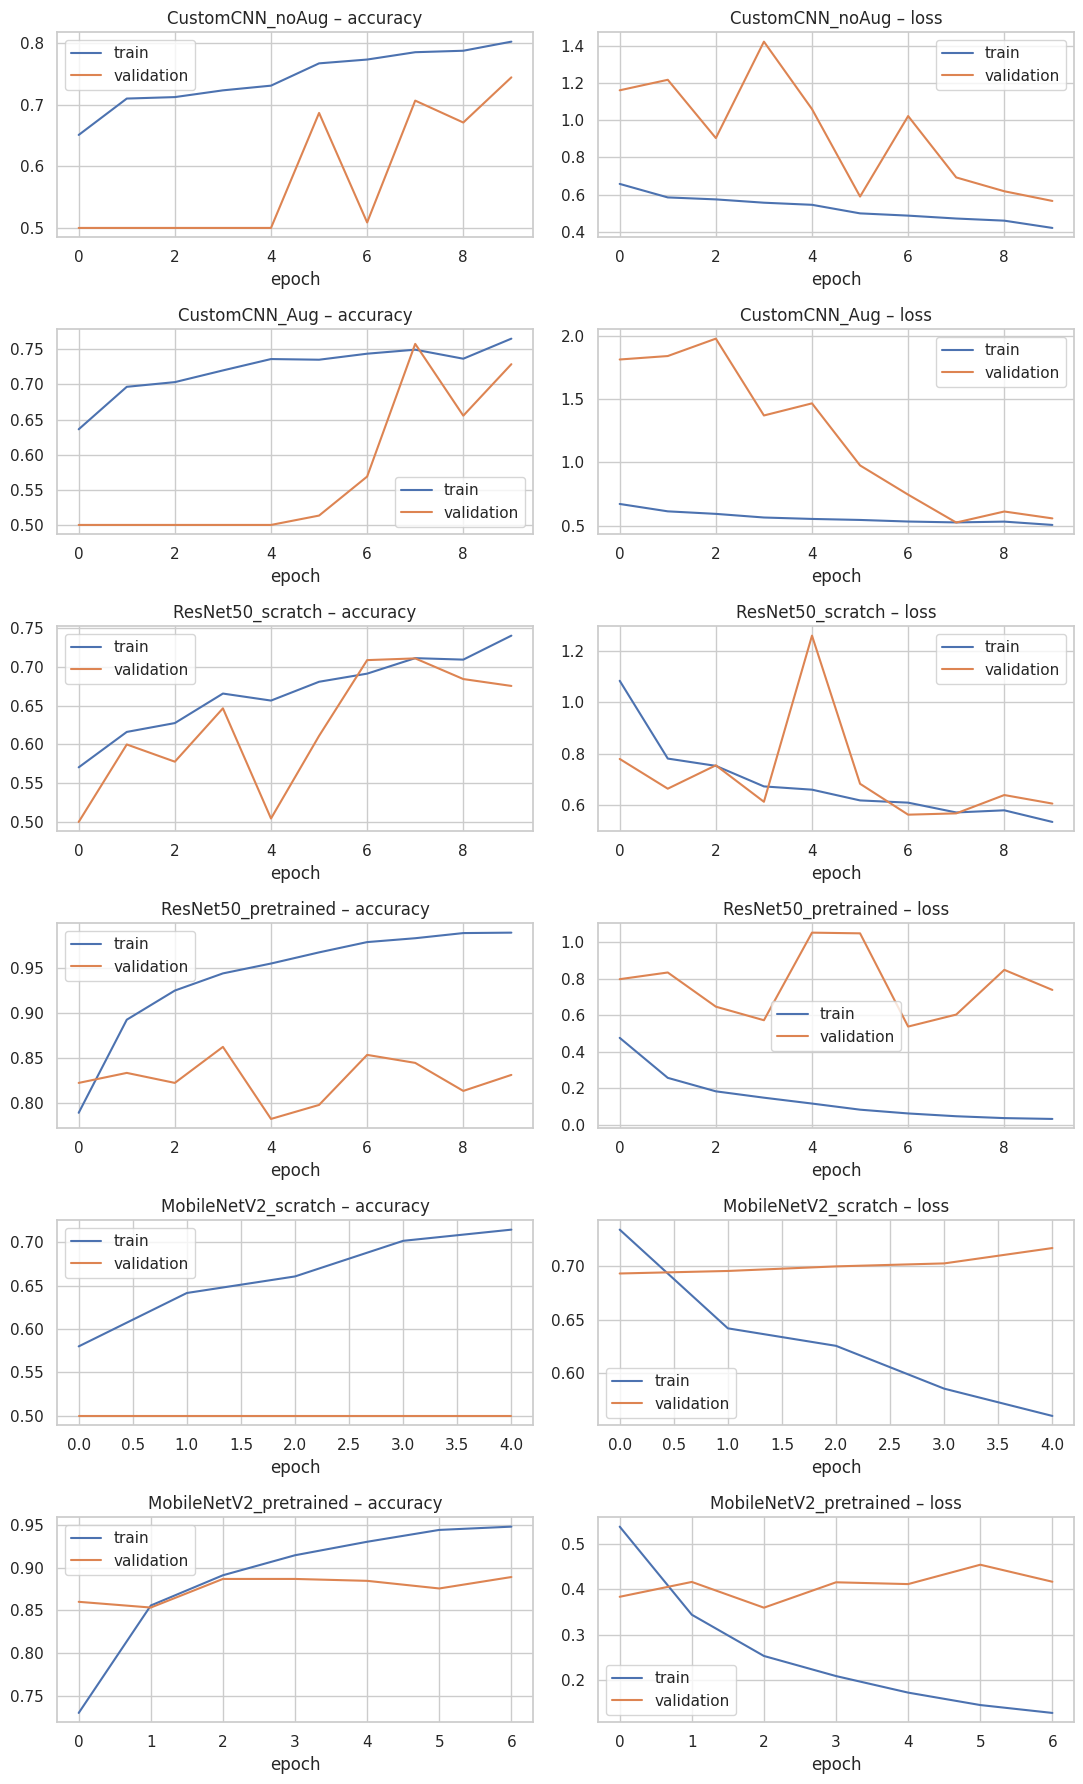

In [24]:
fig, axes = plt.subplots(len(RESULTS), 2, figsize=(11, 3 * len(RESULTS)), squeeze=False)
for row, (name, r) in enumerate(RESULTS.items()):
    h = r["history"]
    axes[row, 0].plot(h["accuracy"], label="train"); axes[row, 0].plot(h["val_accuracy"], label="validation")
    axes[row, 0].set_title(f"{name} – accuracy"); axes[row, 0].set_xlabel("epoch"); axes[row, 0].legend()
    axes[row, 1].plot(h["loss"], label="train"); axes[row, 1].plot(h["val_loss"], label="validation")
    axes[row, 1].set_title(f"{name} – loss"); axes[row, 1].set_xlabel("epoch"); axes[row, 1].legend()
plt.tight_layout(); plt.show()

## Step 6 – Evaluation on the test set
The test images were never used for training or for choosing the best epoch. *Group* is the positive class.


In [25]:
y_true = test_df.y.values
rows = []
for name, r in RESULTS.items():
    pred = (r["prob"] >= 0.5).astype(int)
    rows.append(dict(model=name,
                     accuracy=accuracy_score(y_true, pred),
                     precision=precision_score(y_true, pred, zero_division=0),
                     recall=recall_score(y_true, pred, zero_division=0),
                     f1=f1_score(y_true, pred, zero_division=0)))
metrics = pd.DataFrame(rows).set_index("model").round(3)
metrics.to_csv(WORK / "test_metrics.csv")
display(metrics.style.background_gradient(cmap="Greens"))

best = metrics.f1.idxmax()
print("Best model (highest F1):", best)

,accuracy,precision,recall,f1
model,,,,
CustomCNN_noAug,0.756000,0.853000,0.618000,0.716000
CustomCNN_Aug,0.756000,0.737000,0.796000,0.765000
ResNet50_scratch,0.724000,0.696000,0.796000,0.743000
ResNet50_pretrained,0.858000,0.945000,0.760000,0.842000
MobileNetV2_scratch,0.500000,0.000000,0.000000,0.000000
MobileNetV2_pretrained,0.893000,0.877000,0.916000,0.896000


Best model (highest F1): MobileNetV2_pretrained


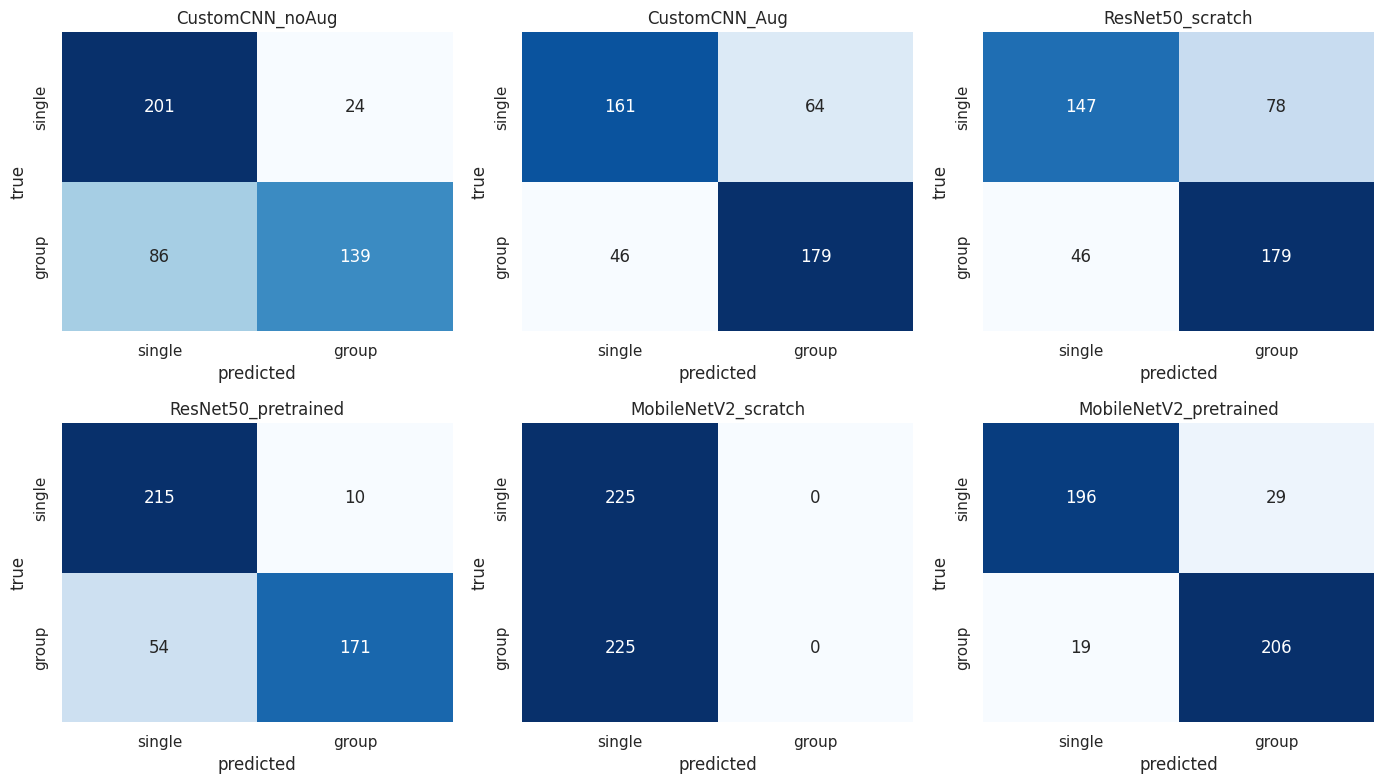

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (name, r) in zip(axes.ravel(), RESULTS.items()):
    cm = confusion_matrix(y_true, (r["prob"] >= 0.5).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(name); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

## Step 7 – Effect of transfer learning and data augmentation
Difference in test F1-score (a positive number means the first option is better).

In [27]:
f1 = metrics.f1
effects = pd.DataFrame({
    "comparison": ["Augmentation (custom CNN): with – without",
                   "Transfer learning (ResNet50): pretrained – scratch",
                   "Transfer learning (MobileNetV2): pretrained – scratch"],
    "F1 difference": [f1["CustomCNN_Aug"] - f1["CustomCNN_noAug"],
                      f1["ResNet50_pretrained"] - f1["ResNet50_scratch"],
                      f1["MobileNetV2_pretrained"] - f1["MobileNetV2_scratch"]]}).set_index("comparison").round(3)
display(effects)

,F1 difference
comparison,
Augmentation (custom CNN): with – without,0.049
Transfer learning (ResNet50): pretrained – scratch,0.099
Transfer learning (MobileNetV2): pretrained – scratch,0.896


## Step 8 – Computational efficiency
Number of parameters, training time and prediction time per image. Absolute times depend on the GPU; the *differences between the models* are what matters.

,parameters_millions,epochs_trained,training_minutes,ms_per_image,f1
CustomCNN_noAug,1.175,10.0,1.801,4.655,0.716
CustomCNN_Aug,1.175,10.0,1.952,1.547,0.765
ResNet50_scratch,23.590,10.0,4.204,6.469,0.743
ResNet50_pretrained,23.590,10.0,4.125,6.089,0.842
MobileNetV2_scratch,2.259,5.0,1.284,3.437,0.000
MobileNetV2_pretrained,2.259,7.0,1.586,3.256,0.896


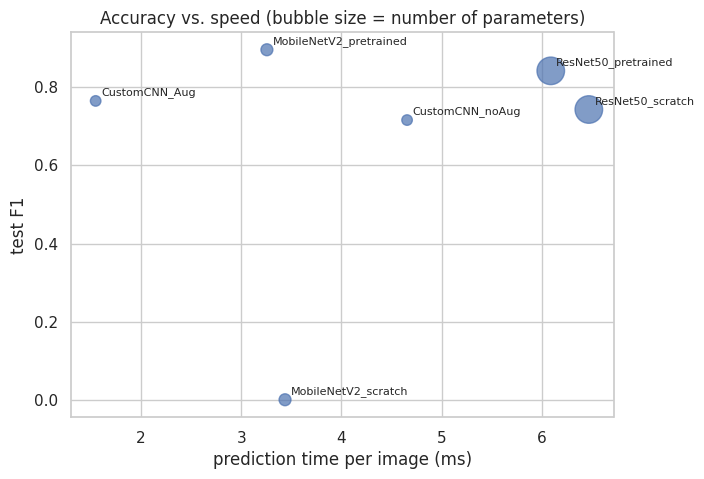

In [28]:
efficiency = pd.DataFrame({n: dict(parameters_millions=r["params"] / 1e6, epochs_trained=r["epochs"],
                                   training_minutes=r["train_min"], ms_per_image=r["infer_ms"], f1=metrics.f1[n])
                           for n, r in RESULTS.items()}).T.astype(float).round(3)
efficiency.to_csv(WORK / "efficiency.csv")
display(efficiency)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(efficiency.ms_per_image, efficiency.f1, s=40 + 15 * efficiency.parameters_millions, alpha=.7)
for n in efficiency.index:
    ax.annotate(n, (efficiency.ms_per_image[n], efficiency.f1[n]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("prediction time per image (ms)"); ax.set_ylabel("test F1")
ax.set_title("Accuracy vs. speed (bubble size = number of parameters)")
plt.show()

## Step 9 – Error analysis
The mistakes of the best model are analysed: which images are wrong, and does the error rate depend on the number or size of the people?

In [29]:
errors = test_df.copy()
errors["prob"]  = RESULTS[best]["prob"]
errors["pred"]  = (errors.prob >= 0.5).astype(int)
errors["wrong"] = errors.pred != errors.y
print(f"{best}: {errors.wrong.sum()} wrong out of {len(errors)} test images")

# The most confident mistakes (|P(group) - 0.5| is large although the answer is wrong)
wrong = errors[errors.wrong].assign(true=lambda d: d.y.map(dict(enumerate(CLASS_NAMES))),
                                    predicted=lambda d: d.pred.map(dict(enumerate(CLASS_NAMES))),
                                    confidence=lambda d: (d.prob - 0.5).abs())
display(wrong.sort_values("confidence", ascending=False)
             [["image_id", "true", "predicted", "n_people", "person_size", "prob", "url"]]
             .head(10).round(3).rename(columns={"prob": "P(group)"}))

MobileNetV2_pretrained: 48 wrong out of 450 test images


,image_id,true,predicted,n_people,person_size,P(group),url
33,5689,single,group,1,0.145,1.000,https://images.cocodataset.org/train2017/00000...
115,106419,single,group,1,0.494,1.000,https://images.cocodataset.org/train2017/00000...
383,484307,group,single,3,0.145,0.000,https://images.cocodataset.org/train2017/00000...
370,315314,group,single,3,0.121,0.001,https://images.cocodataset.org/train2017/00000...
403,471654,single,group,1,0.154,0.997,https://images.cocodataset.org/train2017/00000...
269,168287,group,single,3,0.196,0.004,https://images.cocodataset.org/train2017/00000...
232,454762,single,group,1,0.283,0.995,https://images.cocodataset.org/train2017/00000...
45,455427,single,group,1,0.138,0.989,https://images.cocodataset.org/train2017/00000...
278,140724,single,group,1,0.345,0.988,https://images.cocodataset.org/train2017/00000...
186,496897,single,group,1,0.033,0.986,https://images.cocodataset.org/train2017/00000...


In [30]:
# Error rate by number of people and by person size
errors["people"] = pd.cut(errors.n_people, [0, 1, 4, 7, 1000], labels=["1", "3-4", "5-7", "8+"])
errors["person size"] = pd.qcut(errors.person_size.rank(method="first"), 3, labels=["small", "medium", "large"])

print("Error rate (%) by number of people:")
print((errors.groupby("people", observed=True).wrong.mean() * 100).round(1).to_string())
print("\nError rate (%) by size of the people:")
print((errors.groupby("person size", observed=True).wrong.mean() * 100).round(1).to_string())

Error rate (%) by number of people:
people
1      12.9
3-4    12.7
5-7     1.5
8+      0.0

Error rate (%) by size of the people:
person size
small     10.0
medium     9.3
large     12.7


**Typical reasons for errors** (open some of the URLs from the table above and give examples in the report):
small or distant people · people hidden or cut by the image border · one big person in front with other people far behind · statues, posters, screens or reflections that look like people · label noise (very small extra people that were not counted) · the model recognises the scene ("street", "party") instead of the people · the low resolution (160 px) makes background people disappear.

In [31]:
!ls /content/work/weights /content/work/test_metrics.csv

/content/work/test_metrics.csv

/content/work/weights:
CustomCNN_Aug.weights.h5	   MobileNetV2_scratch.weights.h5
CustomCNN_noAug.weights.h5	   ResNet50_pretrained.weights.h5
MobileNetV2_pretrained.weights.h5  ResNet50_scratch.weights.h5


## Step 10 – Demonstration on your own photo
Run the two cells below and click **Choose files**.
* The **best CNN from Step 6** decides **SINGLE** or **GROUP** – this is the result of the course work.
* As an additional illustration, a ready-made pretrained person detector (Faster R-CNN, from torchvision) draws boxes around the clearly visible people and counts them. It is **not** part of the compared models.

In [38]:
import torch, torchvision
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_fpn, FasterRCNN_MobileNet_V3_Large_FPN_Weights

# 1) the best classifier, rebuilt and loaded from its saved weights
arch, pretrained, augment = RESULTS[best]["config"]
keras.backend.clear_session()
classifier = build_model(arch, pretrained, augment)
classifier.load_weights(WORK / "weights" / f"{best}.weights.h5")

# 2) a pretrained person detector (only for counting people in the demo)
device = "cuda" if torch.cuda.is_available() else "cpu"
detector = fasterrcnn_mobilenet_v3_large_fpn(weights=FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT).to(device).eval()

def predict_photo(path):
    img = Image.open(path).convert("RGB")

    # classification with our CNN (same preprocessing as in training)
    x = tf.round(tf.image.resize(np.array(img), (IMG_SIZE, IMG_SIZE)))[None]
    p_group = float(classifier.predict(x, verbose=0)[0, 0])
    answer = CLASS_NAMES[int(p_group >= 0.5)].upper()

    # counting with the detector (only clearly visible people, same 2 % rule as in Step 1)
    tensor = torchvision.transforms.functional.to_tensor(img).to(device)
    with torch.no_grad():
        out = detector([tensor])[0]
    keep = (out["labels"] == 1) & (out["scores"] >= 0.7)
    keep = keep.nonzero().squeeze(1)
    keep = keep[torchvision.ops.nms(out["boxes"][keep], out["scores"][keep], 0.45)]
    boxes = out["boxes"][keep].cpu().numpy()
    boxes = [b for b in boxes if (b[2] - b[0]) * (b[3] - b[1]) / (img.width * img.height) >= MIN_PERSON_FRAC]

    plt.figure(figsize=(7, 6)); plt.imshow(img); plt.axis("off")
    for b in boxes:
        plt.gca().add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, color="lime", lw=2))
    plt.title(f"{answer}  (P(group) = {p_group:.2f})   |   people counted: {len(boxes)}", fontsize=13)
    plt.show()

Saving images.jpeg to images (1).jpeg


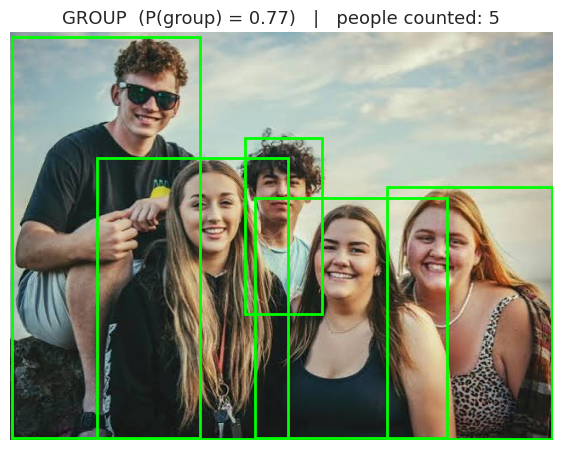

In [40]:
try:
    from google.colab import files
    uploaded = files.upload()                  # opens the "Choose files" dialog
    for file_name in uploaded:
        predict_photo(file_name)
except ImportError:
    print("Not running in Google Colab – call predict_photo('path/to/photo.jpg') instead.")

## Step 11 – Conclusions
*(Fill in with your own numbers from the tables above.)*
1. **Best model:** … (Step 6 – highest F1 and accuracy)
2. **Data augmentation:** … (Step 7 – F1 difference for the custom CNN; compare the gap between the training and validation curves)
3. **Transfer learning:** … (Step 7 – improvement of the pretrained ResNet50 and MobileNetV2 over training from scratch)
4. **Efficiency:** … (Step 8 – is the best model also small and fast? ResNet50 vs. MobileNetV2)
5. **Errors:** … (Step 9 – which images are difficult and why)
6. **Limitations and future work:** labels are created by automatic rules from COCO boxes; images are only 160 × 160 pixels; only two classes (the classifier does not count people); 3 000 images. Next steps: larger input images, more data, a third class for two people, and a model that predicts the number of people directly.